# Can We Trust This Model?

### Notebook 01 — Interpretability and rigorous error analysis
**Telco customer churn** · 7,043 customers · 21 fields

---

Most churn models are shipped on the strength of a single number in a
metrics table. This notebook takes the opposite position: **a model is only as
useful as the evidence that it behaves the way you say it does.**

**The model that gets shipped is the logistic regression** (notebook 02
deploys it). So every analysis below is run on *it*. The LightGBM models are
here as the comparison that tells us whether the extra complexity is worth
having, and, where it is cheap to do, they get the same audits side by side.

Three questions, in order:

| # | Question | Method | Section |
|---|----------|--------|---------|
| 1 | *Does it work, and is a difference between models real?* | Paired bootstrap on validation **and** a paired, corrected test on repeated CV | §3 |
| 2 | *Why does it work, and is that story true?* | Coefficients, exact SHAP, permutation; then a **faithfulness audit with a random-feature control** | §4-§7 |
| 3 | *Where does it fail, and who does it hurt?* | Slice analysis that separates model quality from base rates; calibration; consistency priors; a profit-based threshold checked on the test set | §8-§11 |

---
**Scope and honesty statement**

- This is a *single cross-sectional snapshot*. There is no temporal dimension,
  so nothing here estimates behaviour under concept drift. Notebook 02 (§6)
  builds the monitoring that would detect it.
- **No hyper-parameter search was run.** The project's starting LightGBM
  configuration (400 trees x 31 leaves) is hand-chosen and generous for ~4,500
  rows; it is *not* the library default. Because "linear beats boosting" is only
  a claim about a configuration, we compare against that configuration **and**
  against a small regularised one. What the data actually supports is stated by
  the code in §3, not by this paragraph.
- Explanation is not causation. Nothing in §6 identifies a causal lever.
- Every sentence below that states a number or a finding is printed by a code
  cell from the run itself. Static text holds only definitions and method.

In [1]:
# --- bootstrap -------------------------------------------------------------
# Everything lives in `src/churnml`. The notebook holds narrative; the package
# holds logic. That split is what makes the logic testable -- see tests/.
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("TQDM_DISABLE", "1")      # keep SHAP's progress bars out of the shipped outputs

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Figures must render inline in the shipped notebook *and* be written to
# reports/figures/ by the savefig() calls below. Detecting the kernel with
# get_ipython() is reliable; probing sys.modules for "ipykernel" is not.
try:
    _in_kernel = get_ipython() is not None      # noqa: F821  (IPython builtin)
except NameError:
    _in_kernel = False
matplotlib.use("module://matplotlib_inline.backend_inline" if _in_kernel else "Agg")

ROOT = Path.cwd()
if ROOT.name == "notebooks":        # nbconvert runs with cwd = notebook dir
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import churnml
from churnml import explain as ex
from churnml import evaluate as ev

warnings.filterwarnings("ignore")

# One seed, one source of truth. Nothing below hard-codes a path or a number.
SEED = churnml.SEED
PATHS = churnml.PATHS.ensure()
PATHS.figures.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(f"root      : {ROOT}")
print(f"seed      : {SEED}")
print(f"figures   : {PATHS.figures}")
print(f"churnml   : {churnml.__version__}")

root      : C:\Users\guerr\OneDrive\Desktop\class\churn-ml-showcase
seed      : 42
figures   : C:\Users\guerr\OneDrive\Desktop\class\churn-ml-showcase\reports\figures
churnml   : 1.1.0


In [2]:
# Reproducibility is a file, not a promise. If a metric moves six months from
# now, this table is the first thing anyone will ask for.
env = churnml.environment_manifest()
print(f"python {env['python']}  |  {env['platform']}")
print()
display(pd.DataFrame(env["packages"].items(), columns=["package", "version"]))

python 3.12.0  |  Windows-11-10.0.26100-SP0



,package,version
0,numpy,2.4.4
1,pandas,3.0.6
2,scikit-learn,1.9.1
3,scipy,1.18.1
4,lightgbm,4.7.0
5,xgboost,3.4.1
6,shap,0.52.0
7,matplotlib,3.11.2
8,joblib,1.6.0
9,pydantic,2.13.4


---
## 1 · The data contract

Two fields need care before any model sees them.

### 1.1 `TotalCharges` is a string with 11 blank cells

It arrives as `object` dtype, and eleven cells contain a single space. Because
those are blank *strings* rather than nulls, `pd.isna()` does not see them and
`df.dropna()` removes nothing; a pipeline that expects numbers either errors or
treats the blank as a category. The cell after the cleaning log looks at
**who these customers actually are** before deciding what to do with them.

In [3]:
dataset, splits, clean_log = churnml.load_and_prepare()

print("CLEANING LOG (every step recorded, nothing silent)")
print("=" * 78)
for line in clean_log:
    print("  •", line)
print("=" * 78)
print()
print(f"validation: {dataset.report.n_errors} error(s), {dataset.report.n_warnings} warning(s)")
print(dataset.report)

CLEANING LOG (every step recorded, nothing silent)
  • loaded 7043 rows -> 7043 rows after cleaning
  • TotalCharges: coerced to float64; 11 blank cell(s) -> 0.0 (11 of 11 have tenure 0, 0 churned: not-yet-billed new signups, a structural zero rather than missing data)
  • Churn: binarised to 0/1, positive rate 0.2654

validation: 0 error(s), 1 warning(s)
ValidationReport: 0 error(s), 1 warning(s)
[PASS] schema.columns: all 21 required columns present
[PASS] id.uniqueness: customerID unique
[PASS] nulls.count: no nulls in any column
[PASS] domain.categorical: all categorical values in domain
[PASS] range.numeric: all numeric values within range
[PASS] consistency.addons_without_internet: add-on flags consistent with InternetService
[PASS] consistency.total_vs_tenure: TotalCharges consistent with tenure x MonthlyCharges
[WARN] coercion.TotalCharges: 11 non-numeric cell(s) (blank strings) coerced to NaN (11 rows)


In [4]:
# Who are the blank-TotalCharges customers? The facts are checked (assert), so
# a different extract that broke them would fail here instead of printing a
# sentence that is no longer true.
raw = churnml.load_raw()
blank_mask = pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()
blanks = raw.loc[blank_mask]
n_tenure_zero = int((raw["tenure"] == 0).sum())

print(f"blank TotalCharges cells                : {len(blanks)}")
print(f"  of those, with tenure == 0            : {int((blanks['tenure'] == 0).sum())}")
print(f"  customers with tenure == 0 overall    : {n_tenure_zero}")
print(f"  of those blanks, churned              : {int((blanks['Churn'] == 'Yes').sum())}")
print(f"  raw value                             : {sorted(set(blanks['TotalCharges']))}")
assert (blanks["tenure"] == 0).all() and len(blanks) == n_tenure_zero
assert (blanks["Churn"] == "No").all()

rate_raw = float((raw["Churn"] == "Yes").mean())
rate_if_dropped = float((raw.loc[~blank_mask, "Churn"] == "Yes").mean())
print()
print(f"churn rate, all {len(raw):,} customers          : {rate_raw:.4f}")
print(f"churn rate, if the 11 were dropped          : {rate_if_dropped:.4f}  "
      f"({'higher' if rate_if_dropped > rate_raw else 'lower'}: the dropped customers are all non-churners)")
print(f"churners kept in the cleaned frame          : {int(dataset.frame['_target'].sum())}  of {int((raw['Churn'] == 'Yes').sum())}")
print(f"rows in the cleaned frame                   : {len(dataset.frame)}  of {len(raw)}")

display(Markdown(f"""
**What the data says.** The {len(blanks)} blanks are exactly the {n_tenure_zero} customers with **tenure 0**: new
signups who have not been billed yet, and **none of them churned**. Their total is a *structural zero*, not
missing data. So:

| Response | Consequence |
|---|---|
| Leave as a string | breaks numeric handling, or turns the blank into a category |
| `dropna()` | does nothing, because the blanks are strings; a `to_numeric` + `dropna` clean drops {len(blanks)} brand-new customers and nudges the churn rate from {rate_raw:.4f} to {rate_if_dropped:.4f}: small, but it silently removes exactly the customers with no billing history |
| Impute the mean | gives a customer with zero months of billing a typical lifetime total, contradicting their own `tenure` |
| **Coerce to 0.0** | consistent with tenure 0 (what `data.clean()` does, and logs) |
"""))

blank TotalCharges cells                : 11
  of those, with tenure == 0            : 11
  customers with tenure == 0 overall    : 11
  of those blanks, churned              : 0
  raw value                             : [' ']

churn rate, all 7,043 customers          : 0.2654
churn rate, if the 11 were dropped          : 0.2658  (higher: the dropped customers are all non-churners)
churners kept in the cleaned frame          : 1869  of 1869
rows in the cleaned frame                   : 7043  of 7043



**What the data says.** The 11 blanks are exactly the 11 customers with **tenure 0**: new
signups who have not been billed yet, and **none of them churned**. Their total is a *structural zero*, not
missing data. So:

| Response | Consequence |
|---|---|
| Leave as a string | breaks numeric handling, or turns the blank into a category |
| `dropna()` | does nothing, because the blanks are strings; a `to_numeric` + `dropna` clean drops 11 brand-new customers and nudges the churn rate from 0.2654 to 0.2658: small, but it silently removes exactly the customers with no billing history |
| Impute the mean | gives a customer with zero months of billing a typical lifetime total, contradicting their own `tenure` |
| **Coerce to 0.0** | consistent with tenure 0 (what `data.clean()` does, and logs) |


### 1.2 `"No internet service"` is not a category

Six add-on fields carry a third state. It reads like an answer, but it records
that the question never applied: a customer without internet was never asked
about online backup.

Left as its own level, it splits every genuinely-subscribed population in two
and teaches the model that "declined security" and "has no internet" are
different behaviours. They are not, once you condition on internet service.
`StructuralMissingEncoder` collapses it to a true null.

In [5]:
from churnml.features import StructuralMissingEncoder

addons = list(churnml.ADDON_COLUMNS)
counts = raw[addons].stack().value_counts().rename("rows").to_frame()
counts["share"] = counts["rows"] / counts["rows"].sum()

display(counts.head(12))
print(f"\nCells meaning 'not applicable' rather than 'declined': "
      f"{int(counts.loc['No internet service', 'rows']):,}")
print()
print("Sanity check: are add-on flags internally consistent with InternetService?")
no_net = raw["InternetService"].eq("No")
print(f"  customers with no internet                : {int(no_net.sum()):,}")
print(f"  ...who nonetheless have an active add-on  : "
      f"{int((no_net & raw[addons].eq('Yes').any(axis=1)).sum())}")
print("  (0 is correct -- an impossible state would mean one field is stale)")

enc = StructuralMissingEncoder()
transformed = enc.fit_transform(raw[addons])
print()
print("After encoding:")
print(f"  null add-on cells : {int(transformed.isna().sum().sum()):,}")
print(f"  'No internet service' still present as a level : "
      f"{int((transformed == 'No internet service').sum().sum())}  (must be 0)")

,rows,share
No,18749,0.4437
Yes,14353,0.3397
No internet service,9156,0.2167



Cells meaning 'not applicable' rather than 'declined': 9,156

Sanity check: are add-on flags internally consistent with InternetService?
  customers with no internet                : 1,526
  ...who nonetheless have an active add-on  : 0
  (0 is correct -- an impossible state would mean one field is stale)

After encoding:
  null add-on cells : 9,156
  'No internet service' still present as a level : 0  (must be 0)


---
## 2 · Split discipline

The test set is used **only for the final report in §11**. The validation set
carries every selection decision: which model, which threshold, which
temperature. (Notebook 02 re-reads the same untouched split once more to record
held-out metrics on the registered model; no decision is made from it.)

`assert_no_leakage` runs on every call and raises rather than warns.

In [6]:
print("SPLIT SIZES")
for name, size in splits.sizes().items():
    print(f"  {name:6s} {size:>6,}  ({size / len(dataset.frame):6.1%})")

print()
print("LEAKAGE ASSERTIONS (these raise on violation, they do not warn)")
train_ids = set(splits.train.customerID)
val_ids = set(splits.val.customerID)
test_ids = set(splits.test.customerID)
print(f"  customerID disjoint train/val   : {not (train_ids & val_ids)}")
print(f"  customerID disjoint train/test  : {not (train_ids & test_ids)}")
print(f"  customerID disjoint val/test    : {not (val_ids & test_ids)}")
print(f"  all rows accounted for          : {sum(splits.sizes().values()) == len(dataset.frame)}")

print()
bal = pd.DataFrame({
    "split": ["train", "val", "test"],
    "n": [len(splits.train), len(splits.val), len(splits.test)],
    "churn_rate": [splits.train._target.mean(), splits.val._target.mean(),
                   splits.test._target.mean()],
}).set_index("split")
bal["vs_overall"] = bal.churn_rate - dataset.frame._target.mean()
display(bal)

# Demonstrate the guard is real, not decorative.
leaky = churnml.Splits(
    train=splits.train,
    val=pd.concat([splits.val, splits.train.head(5)]),
    test=splits.test,
)
try:
    churnml.assert_no_leakage(leaky)
    print("!! guard did not fire -- the assertion is broken")
except AssertionError as exc:
    print(f"\nGuard fires as intended:\n  {exc}")

SPLIT SIZES
  train   4,507  ( 64.0%)
  val     1,127  ( 16.0%)
  test    1,409  ( 20.0%)

LEAKAGE ASSERTIONS (these raise on violation, they do not warn)
  customerID disjoint train/val   : True
  customerID disjoint train/test  : True
  customerID disjoint val/test    : True
  all rows accounted for          : True



,n,churn_rate,vs_overall
split,,,
train,4507,0.2654,-0.0000
val,1127,0.2653,-0.0001
test,1409,0.2654,0.0001



Guard fires as intended:
  Customer leakage across splits: train/val=5


In [7]:
# Does customerID reach the model? A model that can memorise IDs scores well
# in validation and fails on the first genuinely new customer.
pre = churnml.build_preprocessor().fit(splits.train.head(500))
encoded_names = list(pre.get_feature_names_out())
banned = {"customerID", "Churn", "_target", "_row_id"}
leaked = [n for n in encoded_names if n in banned or n.startswith("customerID")]

print(f"encoded design matrix width : {len(encoded_names)}")
print(f"identifiers present         : {leaked if leaked else 'none'}")
print(f"first 10 columns            : {encoded_names[:10]}")

encoded design matrix width : 30
identifiers present         : none
first 10 columns            : ['numeric__tenure', 'numeric__MonthlyCharges', 'numeric__TotalCharges', 'ordinal__Contract', 'categorical__gender_Female', 'categorical__gender_Male', 'categorical__Partner_No', 'categorical__Partner_Yes', 'categorical__Dependents_No', 'categorical__Dependents_Yes']


---
## 3 · Which model, and is a difference real?

A logistic regression is the **interpretability floor**. If a boosted ensemble
cannot beat it, the complexity is not earning its cost.

| Model | Why it is here |
|---|---|
| Logistic regression | readable coefficients; the floor; **the model that ships** |
| Random forest | very different inductive bias (averaging, not boosting) |
| LightGBM, project configuration | the usual choice for tabular churn work; 400 trees x 31 leaves |
| LightGBM, regularised | the *fair* opponent: 8 leaves, large leaves, shrinkage, L2; fixed by reasoning about the data size, **not searched** |

A gap against the project configuration only tells us that configuration
over-fits ~4,500 rows. The regularised model is what tells us whether boosting
itself has anything to offer.

Two independent tests answer *"is the difference real?"*:

1. a **paired bootstrap** on the validation rows (both models score the same
   rows, so row-to-row difficulty cancels), and
2. a **paired, corrected resampled t-test** on repeated cross-validation of the
   training data (Nadeau and Bengio, 2003). Folds overlap, so a plain t-test is
   over-confident; the correction fixes that. This test also reflects
   *training-set* variability, which a bootstrap on one validation set cannot.

In [8]:
MODELS = {
    "logreg": churnml.build_logreg(),
    "rf": churnml.build_random_forest(),
    "lgbm": churnml.build_lgbm(),
    "lgbm_small": churnml.build_lgbm_regularised(),
}
LABELS = {"logreg": "Logistic regression", "rf": "Random forest",
          "lgbm": "LightGBM (project config)", "lgbm_small": "LightGBM (regularised)"}

y_train = splits.train._target.to_numpy()
y_val = splits.val._target.to_numpy()
y_test = splits.test._target.to_numpy()

fitted = {}
for key, pipe in MODELS.items():
    pipe.fit(splits.train, splits.train["_target"])
    fitted[key] = pipe

proba = {k: p.predict_proba(splits.val)[:, 1] for k, p in fitted.items()}

rows = []
for key in MODELS:
    m = ev.metric_report(y_val, proba[key], threshold=0.5)
    lo, hi = ev.bootstrap_ci(y_val, proba[key], metric="roc_auc", n_boot=1200)
    m["roc_auc_ci95"] = f"[{lo:.3f}, {hi:.3f}]"
    m["ece"] = ev.expected_calibration_error(y_val, proba[key])
    rows.append({"model": LABELS[key], **m})

display(
    pd.DataFrame(rows)
    .set_index("model")[["roc_auc", "roc_auc_ci95", "pr_auc", "f1", "precision",
                          "recall", "accuracy", "brier", "ece"]]
    .rename(columns={"pr_auc": "pr_auc(AP)", "ece": "ECE"})
)
print("Validation set. Average precision is reported alongside ROC-AUC: on a 26.5%")
print("positive class, ROC-AUC can flatter weak models by rewarding easy negatives.")

,roc_auc,roc_auc_ci95,pr_auc(AP),f1,precision,recall,accuracy,brier,ECE
model,,,,,,,,,
Logistic regression,0.8507,"[0.826, 0.875]",0.6755,0.5985,0.7078,0.5184,0.8154,0.1320,0.0306
Random forest,0.8412,"[0.815, 0.867]",0.6529,0.5426,0.6650,0.4582,0.7950,0.1360,0.0291
LightGBM (project config),0.8249,"[0.799, 0.851]",0.6271,0.5610,0.6160,0.5151,0.7862,0.1469,0.0573
LightGBM (regularised),0.8500,"[0.825, 0.874]",0.6676,0.5900,0.6906,0.5151,0.8101,0.1327,0.0231


Validation set. Average precision is reported alongside ROC-AUC: on a 26.5%
positive class, ROC-AUC can flatter weak models by rewarding easy negatives.


In [9]:
# Repeated CV on the TRAINING data. Every model sees identical folds, so the
# comparison below is paired.
cv = ev.cross_validate(MODELS, splits.train, y_train, n_splits=5, n_repeats=3)
display(cv.summary.rename(index=LABELS).round(4))

others = [k for k in MODELS if k != "logreg"]
rows = []
for other in others:
    for metric, name in (("pr_auc", "PR-AUC"), ("roc_auc", "ROC-AUC")):
        d = cv.paired_difference("logreg", other, metric=metric)
        rows.append({"logreg minus": LABELS[other], "metric": name, "mean diff": d["mean_diff"],
                     "95% CI": f"[{d['ci_low']:+.4f}, {d['ci_high']:+.4f}]", "t": d["t"],
                     "p": d["p_value"], "significant": d["significant"]})
cv_table = pd.DataFrame(rows)
print("\nPAIRED, CORRECTED CV TEST on the training data (logistic regression minus competitor):")
display(cv_table.set_index(["logreg minus", "metric"]).round(4))
print(f"(The widest per-fold PR-AUC range is {max(cv.spread(k) for k in MODELS):.3f}; that range is a noise")
print("scale to eyeball, NOT the test -- the corrected t-test above is the test.)")

,pr_auc_mean,pr_auc_std,pr_auc_min,pr_auc_max,roc_auc_mean,roc_auc_std
Logistic regression,0.6621,0.0266,0.5992,0.7025,0.8450,0.0096
Random forest,0.6571,0.0251,0.5941,0.6956,0.8396,0.0105
LightGBM (project config),0.6228,0.0274,0.5503,0.6602,0.8195,0.0148
LightGBM (regularised),0.6593,0.0248,0.5943,0.6875,0.8435,0.0099



PAIRED, CORRECTED CV TEST on the training data (logistic regression minus competitor):


mean diff              95% CI      t      p  significant
logreg minus              metric                                                           
Random forest             PR-AUC      0.0050  [-0.0093, +0.0192] 0.7469 0.4675        False
                          ROC-AUC     0.0054  [-0.0004, +0.0111] 1.9994 0.0654        False
LightGBM (project config) PR-AUC      0.0393  [+0.0158, +0.0628] 3.5835 0.0030         True
                          ROC-AUC     0.0255  [+0.0143, +0.0367] 4.8977 0.0002         True
LightGBM (regularised)    PR-AUC      0.0028  [-0.0074, +0.0130] 0.5916 0.5635        False
                          ROC-AUC     0.0014  [-0.0033, +0.0062] 0.6608 0.5195        False

(The widest per-fold PR-AUC range is 0.110; that range is a noise
scale to eyeball, NOT the test -- the corrected t-test above is the test.)


In [10]:
# The same question on the validation rows: paired bootstrap.
rows = []
boot = {}
for other in others:
    for metric, name in (("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC")):
        d = ev.paired_bootstrap_delta(y_val, proba["logreg"], proba[other], metric=metric)
        boot[(other, metric)] = d
        rows.append({"logreg minus": LABELS[other], "metric": name, "delta": d["delta"],
                     "95% CI": f"[{d['ci_low']:+.4f}, {d['ci_high']:+.4f}]",
                     "P(logreg better)": d["p_better"], "excludes zero": d["significant"]})
print("PAIRED BOOTSTRAP on the validation rows (logistic regression minus competitor):")
display(pd.DataFrame(rows).set_index(["logreg minus", "metric"]).round(4))

PAIRED BOOTSTRAP on the validation rows (logistic regression minus competitor):


delta              95% CI  P(logreg better)  excludes zero
logreg minus              metric                                                             
Random forest             ROC-AUC 0.0095  [-0.0002, +0.0194]            0.9720          False
                          PR-AUC  0.0226  [-0.0019, +0.0447]            0.9650          False
LightGBM (project config) ROC-AUC 0.0258  [+0.0113, +0.0411]            0.9990           True
                          PR-AUC  0.0484  [+0.0167, +0.0842]            0.9985           True
LightGBM (regularised)    ROC-AUC 0.0008  [-0.0066, +0.0084]            0.5845          False
                          PR-AUC  0.0079  [-0.0099, +0.0263]            0.8085          False

In [11]:
# What do the two tests, taken together, actually support? Computed, not typed.
def verdict(other):
    cv_sig = {m: cv.paired_difference("logreg", other, metric=m)["significant"] for m in ("pr_auc", "roc_auc")}
    cv_dir = {m: cv.paired_difference("logreg", other, metric=m)["mean_diff"] for m in ("pr_auc", "roc_auc")}
    boot_sig = boot[(other, "roc_auc")]["significant"]
    if all(cv_sig.values()) and boot_sig and all(v > 0 for v in cv_dir.values()):
        return "logistic regression is **better**", "both tests agree"
    if not any(cv_sig.values()) and not boot_sig:
        return "**no distinguishable difference**", "neither test finds one"
    return "**mixed evidence**", "the two tests disagree"

lines = []
for other in others:
    outcome, why = verdict(other)
    lines.append(f"- vs **{LABELS[other]}**: {outcome} ({why}).")
display(Markdown("**What the evidence supports**\n\n" + "\n".join(lines) + """

So the defensible claim is exactly as wide as the table: against the configurations marked *better*, a plain
regularised linear model wins; where the result reads *no distinguishable difference*, boosting is simply not
earning its complexity here. This is a statement about **these configurations on ~4,500 training rows**, not
about gradient boosting in general."""))

**What the evidence supports**

- vs **Random forest**: **no distinguishable difference** (neither test finds one).
- vs **LightGBM (project config)**: logistic regression is **better** (both tests agree).
- vs **LightGBM (regularised)**: **no distinguishable difference** (neither test finds one).

So the defensible claim is exactly as wide as the table: against the configurations marked *better*, a plain
regularised linear model wins; where the result reads *no distinguishable difference*, boosting is simply not
earning its complexity here. This is a statement about **these configurations on ~4,500 training rows**, not
about gradient boosting in general.

---
## 4 · Global explanation of the model that ships

Four views of the *same* logistic regression, plus the ensemble for contrast:

- **Coefficients**: exact and readable, but each one is conditional on every
  other input. With correlated inputs a coefficient can even take the *opposite*
  sign to the raw association; the cell below checks for exactly that.
- **Exact SHAP**: for a linear model SHAP is closed-form (`coef x (value - mean)`
  in log-odds), so there is no sampling noise. It shares the coefficients'
  conditional nature but reports it per customer.
- **Permutation importance**: model-agnostic; how much ROC-AUC dies when a raw
  input is shuffled. Generous to correlated features (they cover for each other).
- **Split-count importance** (LightGBM only; what `feature_importances_` returns
  by default): included so it can be *demoted* with evidence. It counts how often
  a feature is used in a split, which favours continuous features that simply
  offer more candidate split points.

Derived features (`charges_per_month`, `num_addons`, ...) are handed back to the
raw columns they are computed from, so every method ranks the same 19 raw inputs.

In [12]:
coef = churnml.extract_linear_coefficients(fitted["logreg"], top_n=16)
display(coef)

# Do any large coefficients point the OPPOSITE way to the raw association? That is
# the signature of correlated inputs sharing credit, and it is the reason a
# coefficient must not be read as "the effect of X".
train = splits.train
overall = float(train["_target"].mean())
flips = []
for name, c in zip(coef["feature"], coef["coef"]):
    stem = name.replace("categorical__", "")
    for col in ("InternetService", "PaymentMethod", "MultipleLines", "PaperlessBilling", "SeniorCitizen",
                "Partner", "Dependents", "PhoneService", "gender"):
        if name.startswith("categorical__") and stem.startswith(col + "_"):
            level = stem[len(col) + 1:]
            present = train[col].astype(str).eq(level)
            if present.sum() >= 50:
                raw_gap = float(train.loc[present, "_target"].mean() - overall)
                if abs(raw_gap) >= 0.03 and np.sign(raw_gap) != np.sign(c):     # ignore trivial gaps (<3 points)
                    flips.append((f"{col} = {level}", c, raw_gap, float(train.loc[present, "_target"].mean())))
if flips:
    print("\nCoefficient sign DISAGREES with the raw association for:")
    for label, c, gap, rate in flips:
        print(f"  {label:34s} coefficient {c:+.3f}   but churn rate {rate:.1%} ({gap:+.1%} vs overall)")
    mc_corr = float(np.corrcoef(train["MonthlyCharges"].astype(float),
                                train["InternetService"].eq("Fiber optic").astype(float))[0, 1])
    print(f"\ncorr(MonthlyCharges, InternetService=Fiber optic) = {mc_corr:+.2f}: the price premium that comes with")
    print("a service is carried by the MonthlyCharges coefficient, so the service level can take the opposite sign.")
else:
    print("\nNo large coefficient disagrees in sign with its raw association.")
if (train["PhoneService"].eq("No") == train["MultipleLines"].eq("No phone service")).all():
    print("\nNote: 'PhoneService = No' and 'MultipleLines = No phone service' are the SAME customers, so they are")
    print("perfectly collinear columns and share one coefficient (the model cannot tell them apart).")
print("\nRead each coefficient as 'holding every other input fixed' -- not as 'the effect of X'.")

,feature,coef,abs_coef,direction
1,numeric__MonthlyCharges,2.4230,2.4230,increases risk
3,ordinal__Contract,-0.9808,0.9808,decreases risk
0,numeric__tenure,-0.9454,0.9454,decreases risk
17,categorical__InternetService_No,0.7931,0.7931,increases risk
10,categorical__PhoneService_No,0.6641,0.6641,increases risk
13,categorical__MultipleLines_No phone service,0.6641,0.6641,increases risk
16,categorical__InternetService_Fiber optic,-0.3808,0.3808,decreases risk
27,derived__num_addons,-0.3788,0.3788,decreases risk
19,categorical__PaperlessBilling_Yes,0.3768,0.3768,increases risk
8,categorical__Dependents_No,0.3458,0.3458,increases risk



Coefficient sign DISAGREES with the raw association for:
  InternetService = No               coefficient +0.793   but churn rate 7.5% (-19.0% vs overall)
  InternetService = Fiber optic      coefficient -0.381   but churn rate 42.2% (+15.7% vs overall)
  Partner = Yes                      coefficient +0.237   but churn rate 19.5% (-7.1% vs overall)

corr(MonthlyCharges, InternetService=Fiber optic) = +0.78: the price premium that comes with
a service is carried by the MonthlyCharges coefficient, so the service level can take the opposite sign.

Note: 'PhoneService = No' and 'MultipleLines = No phone service' are the SAME customers, so they are
perfectly collinear columns and share one coefficient (the model cannot tell them apart).

Read each coefficient as 'holding every other input fixed' -- not as 'the effect of X'.


In [13]:
val = splits.val

# --- the shipped model: logistic regression ---------------------------------
perm_lr = ex.permutation_importance_frame(fitted["logreg"], val, y_val, n_repeats=8, input_features=True)
shap_lr = ex.compute_shap(fitted["logreg"], val, max_samples=len(val))
shap_lr_roll = ex.roll_up_to_inputs(shap_lr.abs_mean(), fitted["logreg"], shap_lr.names)

# --- the ensemble, for contrast ----------------------------------------------
perm_gb = ex.permutation_importance_frame(fitted["lgbm"], val, y_val, n_repeats=8, input_features=True)
shap_gb = ex.compute_shap(fitted["lgbm"], val, max_samples=len(val))
shap_gb_roll = ex.roll_up_to_inputs(shap_gb.abs_mean(), fitted["lgbm"], shap_gb.names)
split_names = ex.encoded_feature_names(fitted["lgbm"])
split_counts = ex.impurity_importance_frame(fitted["lgbm"], split_names)
split_roll = ex.roll_up_to_inputs(split_counts.set_index("feature")["impurity_importance"], fitted["lgbm"], split_names)

compare_lr = pd.DataFrame({
    "permutation (ROC-AUC drop)": perm_lr.set_index("feature").importance,
    "mean |SHAP| (log-odds)": shap_lr_roll,
}).dropna().sort_values("mean |SHAP| (log-odds)", ascending=False)
compare_gb = pd.DataFrame({
    "permutation (ROC-AUC drop)": perm_gb.set_index("feature").importance,
    "mean |SHAP| (log-odds)": shap_gb_roll,
    "split count": split_roll,
}).dropna().sort_values("mean |SHAP| (log-odds)", ascending=False)

print("LOGISTIC REGRESSION (the shipped model)")
display(compare_lr.head(12).round(4))
print(f"\nLIGHTGBM, project config (for contrast)   [{len(compare_gb)} raw inputs compared]")
display(compare_gb.head(12).round(4))

LOGISTIC REGRESSION (the shipped model)


,permutation (ROC-AUC drop),mean |SHAP| (log-odds)
MonthlyCharges,0.2841,2.2664
tenure,0.0855,1.3423
Contract,0.0616,0.8299
TotalCharges,0.3205,0.6712
InternetService,0.0118,0.4854
MultipleLines,0.0044,0.2217
Partner,0.0001,0.2102
gender,0.0000,0.2102
PaperlessBilling,0.0082,0.2016
PaymentMethod,0.0067,0.1875



LIGHTGBM, project config (for contrast)   [19 raw inputs compared]


,permutation (ROC-AUC drop),mean |SHAP| (log-odds),split count
Contract,0.1063,0.9358,255.0000
tenure,0.0625,0.8312,"3,187.5000"
MonthlyCharges,0.0179,0.5885,"3,322.0000"
TotalCharges,0.0123,0.4595,"2,920.5000"
InternetService,0.0289,0.3997,85.0000
PaymentMethod,0.0037,0.2718,541.0000
MultipleLines,0.0007,0.1332,179.0000
Dependents,0.0049,0.0987,130.0000
PaperlessBilling,0.0018,0.0947,239.0000
SeniorCitizen,0.0027,0.0873,148.0000


In [14]:
agree_lr = ex.importance_agreement(perm_lr.rename(columns={"importance_mean": "permutation"}), shap_lr_roll)
agree_gb = ex.importance_agreement(perm_gb.rename(columns={"importance_mean": "permutation"}), shap_gb_roll)
display(pd.concat([agree_lr.assign(model="logreg"), agree_gb.assign(model="lgbm")]).set_index("model").round(4))

top5 = lambda s: set(s.sort_values(ascending=False).head(5).index)
overlap_lr = top5(compare_lr["permutation (ROC-AUC drop)"]) & top5(compare_lr["mean |SHAP| (log-odds)"])

# the split-count bias claim, tested rather than asserted
cont = {"tenure", "MonthlyCharges", "TotalCharges"}
rank_split = split_roll.rank(ascending=False)
rank_shap = shap_gb_roll.rank(ascending=False)
bias_rows = sorted(cont, key=lambda f: rank_split[f])
bias_text = ", ".join(f"{f} (split-count rank {int(rank_split[f])} vs SHAP rank {int(rank_shap[f])})" for f in bias_rows)

rho_lr, rho_gb = float(agree_lr.spearman_rho.iloc[0]), float(agree_gb.spearman_rho.iloc[0])
display(Markdown(f"""
**Agreement between independent methods.** For the shipped logistic regression, permutation and SHAP rank the
{int(agree_lr.n_features.iloc[0])} raw inputs with Spearman rho = **{rho_lr:.2f}**, and they share {len(overlap_lr)} of their top 5
({", ".join(sorted(overlap_lr))}). For the LightGBM they agree at rho = **{rho_gb:.2f}**. Where the methods disagree, the specific
number should be treated as unknown.

**The split-count bias, checked.** Continuous inputs under split-count importance vs SHAP: {bias_text}.
{"Split-count importance ranks the continuous fields higher than SHAP does, which is the predicted bias." if all(rank_split[f] <= rank_shap[f] for f in cont) else "The predicted bias (continuous fields ranked higher by split count) is NOT uniformly present here, so this notebook does not claim it."}
"""))

,n_features,spearman_rho,spearman_p,kendall_tau,kendall_p,verdict
model,,,,,,
logreg,19,0.5889,0.0080,0.4531,0.0084,methods disagree -- investigate before trustin...
lgbm,19,0.8678,0.0000,0.7470,0.0000,methods broadly agree



**Agreement between independent methods.** For the shipped logistic regression, permutation and SHAP rank the
19 raw inputs with Spearman rho = **0.59**, and they share 5 of their top 5
(Contract, InternetService, MonthlyCharges, TotalCharges, tenure). For the LightGBM they agree at rho = **0.87**. Where the methods disagree, the specific
number should be treated as unknown.

**The split-count bias, checked.** Continuous inputs under split-count importance vs SHAP: MonthlyCharges (split-count rank 1 vs SHAP rank 3), tenure (split-count rank 2 vs SHAP rank 2), TotalCharges (split-count rank 3 vs SHAP rank 4).
Split-count importance ranks the continuous fields higher than SHAP does, which is the predicted bias.


---
## 5 · Heterogeneity: the average effect can hide the individuals

A partial-dependence (PDP) curve answers *"on average, what does changing tenure
do?"* It silently averages over everyone. **Individual conditional expectation
(ICE)** curves compute the curve *per customer*; where they spread out, one
average line misdescribes most of the people it is applied to.

Part of any spread is purely mechanical: even a linear model has different
probability-scale slopes for different customers because of the logistic link.
So both models are shown, and the ratio is reported for each rather than assumed.

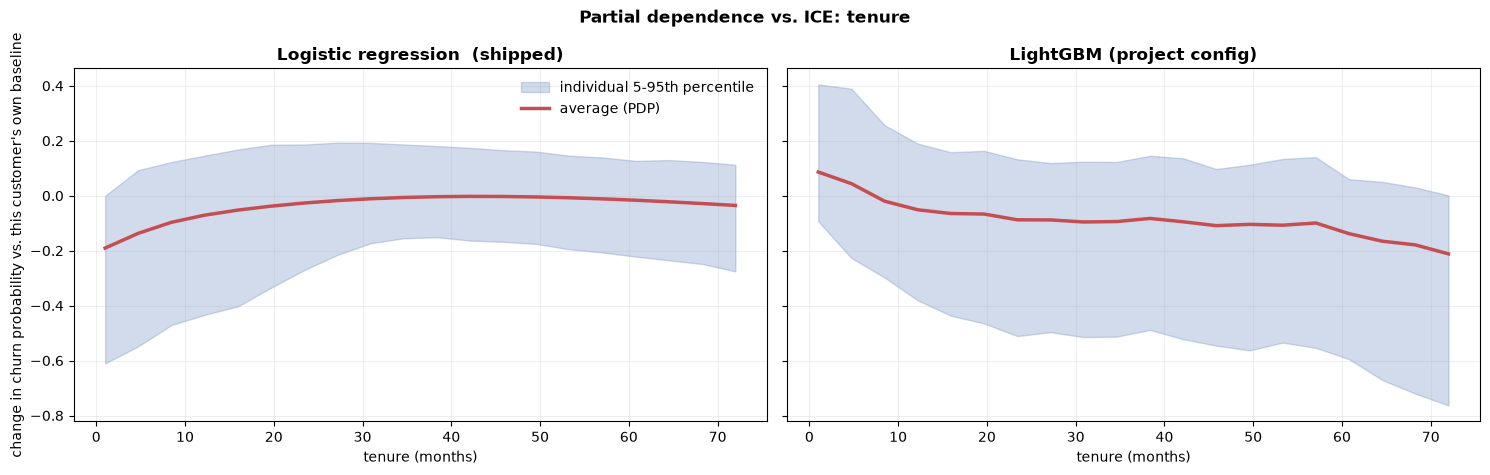

,mean |individual effect|,spread between customers,ratio (spread / effect)
Logistic regression,0.0913,0.1249,1.3680
LightGBM (project config),0.1442,0.2014,1.3964


Tenure heterogeneity, computed: **Logistic regression**: spread/effect = 1.37x; **LightGBM (project config)**: spread/effect = 1.40x. The between-customer spread exceeds the average effect for Logistic regression, LightGBM (project config), so a single PDP line should not be read as 'the effect of tenure' for individuals.

In [15]:
def ice_for(key, feature, grid=None):
    g, pdp_line, ice = ex.partial_dependence(fitted[key], splits.val, feature, grid=grid)
    return g, ex.ice_spread(ice, g)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
ratios = {}
for ax, key in zip(axes, ("logreg", "lgbm")):
    g, spread = ice_for(key, "tenure")
    ax.fill_between(g, spread.ice_p05, spread.ice_p95, alpha=0.25, color="#4C72B0", label="individual 5-95th percentile")
    ax.plot(g, spread.pdp, color="#C44E52", lw=2.5, label="average (PDP)")
    ax.set_xlabel("tenure (months)")
    ax.set_title(f"{LABELS[key]}" + ("  (shipped)" if key == "logreg" else ""), weight="bold")
    ax.grid(alpha=0.2)
    ratios[key] = (float(spread.mean_abs_individual_effect.mean()), float(spread.sd_across_population.mean()))
axes[0].set_ylabel("change in churn probability vs. this customer's own baseline")
axes[0].legend(frameon=False)
fig.suptitle("Partial dependence vs. ICE: tenure", weight="bold")
plt.tight_layout()
fig.savefig(PATHS.figures / "01_pdp_ice_tenure.png", dpi=140, bbox_inches="tight")
plt.show()

table = pd.DataFrame(
    {LABELS[k]: {"mean |individual effect|": e, "spread between customers": s, "ratio (spread / effect)": s / e}
     for k, (e, s) in ratios.items()}
).T
display(table.round(4))
parts = [f"**{LABELS[k]}**: spread/effect = {s / e:.2f}x" for k, (e, s) in ratios.items()]
display(Markdown("Tenure heterogeneity, computed: " + "; ".join(parts) + ". "
                 + ("The between-customer spread exceeds the average effect for "
                    + ", ".join(LABELS[k] for k, (e, s) in ratios.items() if s > e)
                    + ", so a single PDP line should not be read as 'the effect of tenure' for individuals."
                    if any(s > e for e, s in ratios.values())
                    else "For both models the individual curves agree closely with the average.")))

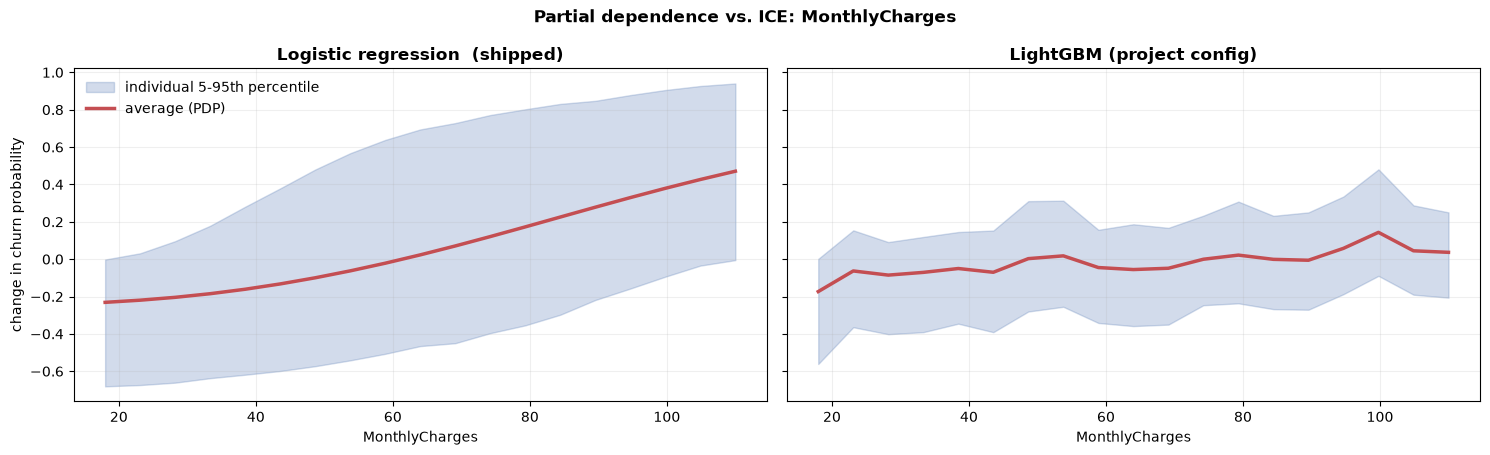

In [16]:
# The same view for MonthlyCharges.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for ax, key in zip(axes, ("logreg", "lgbm")):
    g, spread = ice_for(key, "MonthlyCharges", grid=np.linspace(18.0, 110.0, 19))
    ax.fill_between(g, spread.ice_p05, spread.ice_p95, alpha=0.25, color="#4C72B0", label="individual 5-95th percentile")
    ax.plot(g, spread.pdp, color="#C44E52", lw=2.5, label="average (PDP)")
    ax.set_xlabel("MonthlyCharges")
    ax.set_title(LABELS[key] + ("  (shipped)" if key == "logreg" else ""), weight="bold")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("change in churn probability")
axes[0].legend(frameon=False)
fig.suptitle("Partial dependence vs. ICE: MonthlyCharges", weight="bold")
plt.tight_layout()
fig.savefig(PATHS.figures / "02_pdp_ice_charges.png", dpi=140, bbox_inches="tight")
plt.show()

---
## 6 · Local explanation: why *this* customer (shipped model)

Four archetypes, chosen to stress different failure modes:

1. **Highest predicted risk**: what the model keys on when it is most certain
2. **Confidently wrong**: the highest score given to someone who stayed
3. **Confidently right, lowest score**: a customer the model correctly ignores
4. **Near the decision boundary**: where a business decision actually turns

Attributions are the exact linear SHAP values, in log-odds.

**Counterfactual caveat, stated before you read the numbers:** the analysis
below finds how a *score* moves when a field is edited. It does **not**
establish that changing that field would change the outcome: features are
correlated, the data is observational, and a customer told "raise your tenure"
cannot do so. Treat these as *conversation starters for a retention review*,
never as interventions.

In [17]:
def pick_cases(y, p):
    """One representative row per decision archetype (all chosen from the same score vector)."""
    correct = ((p >= 0.5) == (y == 1))
    wrong_high = np.where(~correct & (p > 0.5))[0]
    right_low = np.where(correct & (p < 0.3))[0]
    return {
        "highest risk": int(np.argmax(p)),
        "confidently wrong": int(wrong_high[np.argmax(p[wrong_high])]),
        "confidently ignored": int(right_low[np.argmin(p[right_low])]),
        "near boundary": int(np.argmin(np.abs(p - 0.5))),
    }

val_frame = splits.val.reset_index(drop=True)
p_lr = proba["logreg"]
cases = pick_cases(y_val, p_lr)

summary = pd.DataFrame([
    {
        "archetype": k,
        "customerID": val_frame.customerID.iloc[i],
        "predicted": p_lr[i],
        "actual": "churned" if y_val[i] == 1 else "stayed",
        "correct": bool((p_lr[i] >= 0.5) == (y_val[i] == 1)),
        "tenure": val_frame.tenure.iloc[i],
        "contract": val_frame.Contract.iloc[i],
        "monthly": val_frame.MonthlyCharges.iloc[i],
        "internet": val_frame.InternetService.iloc[i],
    }
    for k, i in cases.items()
]).set_index("archetype")
display(summary)

,customerID,predicted,actual,correct,tenure,contract,monthly,internet
archetype,,,,,,,,
highest risk,3988-RQIXO,0.8977,churned,True,1,Month-to-month,91.3000,Fiber optic
confidently wrong,4912-PIGUY,0.8906,stayed,False,1,Month-to-month,84.6000,Fiber optic
confidently ignored,6928-ONTRW,0.0022,stayed,True,72,Two year,19.7000,No
near boundary,6778-YSNIH,0.5001,stayed,False,2,Month-to-month,59.0000,DSL


In [18]:
for archetype, i in cases.items():
    wf = shap_lr.waterfall(i, top=8)
    print("=" * 74)
    print(f"{archetype.upper()}  --  {val_frame.customerID.iloc[i]}")
    print(f"  predicted churn risk {p_lr[i]:.3f}   (actually {'churned' if y_val[i] == 1 else 'stayed'})")
    print("=" * 74)
    for _, r in wf.iterrows():
        arrow = "▲" if r.shap_value > 0 else "▼"
        print(f"  {r.feature:34s} {arrow} {abs(r.shap_value):.4f}  {r.direction}")
    print()

HIGHEST RISK  --  3988-RQIXO
  predicted churn risk 0.898   (actually churned)
  MonthlyCharges                     ▲ 2.2792  pushes risk UP
  tenure                             ▲ 1.2201  pushes risk UP
  Contract                           ▲ 0.7356  pushes risk UP
  charges_per_month                  ▲ 0.4248  pushes risk UP
  TotalCharges                       ▼ 0.2698  pushes risk DOWN
  SeniorCitizen_1                    ▲ 0.2416  pushes risk UP
  PaymentMethod_Electronic check     ▲ 0.2315  pushes risk UP
  InternetService_No                 ▼ 0.2141  pushes risk DOWN

CONFIDENTLY WRONG  --  4912-PIGUY
  predicted churn risk 0.891   (actually stayed)
  MonthlyCharges                     ▲ 1.7383  pushes risk UP
  tenure                             ▲ 1.2201  pushes risk UP
  Contract                           ▲ 0.7356  pushes risk UP
  charges_per_month                  ▲ 0.5318  pushes risk UP
  num_addons                         ▲ 0.3561  pushes risk UP
  TotalCharges             

In [19]:
# A counterfactual, done carefully. TotalCharges is the running sum of billing, so
# editing tenure or MonthlyCharges while leaving TotalCharges alone creates a
# customer who cannot exist. Each row below is shown BOTH ways, so the size of
# that mistake is visible rather than assumed.
i = cases["highest risk"]
row = val_frame.iloc[[i]].copy()
base = float(p_lr[i])
print(f"Customer {val_frame.customerID.iloc[i]}: predicted risk {base:.3f}")
print()

def edited(**changes):
    naive = row.copy()
    for col, value in changes.items():
        naive[col] = value
    consistent = naive.copy()
    if "tenure" in changes or "MonthlyCharges" in changes:
        consistent["TotalCharges"] = round(float(consistent["tenure"].iloc[0]) * float(consistent["MonthlyCharges"].iloc[0]), 2)
    return naive, consistent

tenure_probe = min(60, int(row.tenure.iloc[0]) + 24)
monthly_probe = float(np.median(val_frame.MonthlyCharges))
candidates = []
for label, changes in [
    (f"tenure -> {tenure_probe} months", {"tenure": tenure_probe}),
    (f"MonthlyCharges -> median ({monthly_probe:.2f})", {"MonthlyCharges": monthly_probe}),
    ("Contract -> Two year", {"Contract": "Two year"}),
    ("InternetService -> DSL", {"InternetService": "DSL"}),
]:
    naive, consistent = edited(**changes)
    p_naive = float(fitted["logreg"].predict_proba(naive)[0, 1])
    p_cons = float(fitted["logreg"].predict_proba(consistent)[0, 1])
    candidates.append({"hypothetical change": label, "new risk (naive edit)": p_naive,
                       "new risk (TotalCharges kept consistent)": p_cons, "shift (consistent)": p_cons - base})
display(pd.DataFrame(candidates).sort_values("shift (consistent)").round(4))
print("""
These are hypothetical manipulations of a record, not recommended actions.
A model that learned correlation cannot tell you which lever, if any, a human
can actually pull -- and 'increase tenure' is not a lever anyone controls.
Where the two columns differ, the naive edit built an impossible customer.
""")

Customer 3988-RQIXO: predicted risk 0.898



,hypothetical change,new risk (naive edit),new risk (TotalCharges kept consistent),shift (consistent)
0,tenure -> 25 months,0.9420,0.5908,-0.3068
2,Contract -> Two year,0.5951,0.5951,-0.3026
1,MonthlyCharges -> median (71.10),0.6316,0.7025,-0.1952
3,InternetService -> DSL,0.9283,0.9283,0.0306



These are hypothetical manipulations of a record, not recommended actions.
A model that learned correlation cannot tell you which lever, if any, a human
can actually pull -- and 'increase tenure' is not a lever anyone controls.
Where the two columns differ, the naive edit built an impossible customer.



---
## 7 · Are the explanations even true?

A SHAP plot is a claim about the model. **Test the claim.**

For each *k*, shuffle the *k* raw inputs the explanation ranks highest (this
breaks their link to the label while keeping their distribution) and recompute
ROC-AUC. A drop alone proves nothing, because *any* informative input hurts when
destroyed. The evidence is the **control**: how does shuffling the top-*k* compare
with shuffling *k randomly chosen* inputs?

- `share_random_as_damaging` = the share of random same-size feature sets that
  hurt **at least as much** as the explanation's top-*k*. Small is good.
- Two bars are shown. The **strict** bar (<= 10%) asks whether the top-*k* is among
  the very most damaging subsets; with correlated inputs no ranking is guaranteed
  to pick the single worst subset, so it will not always be met. The **verdict**
  uses a bar of <= 30% (more damaging than 70% of random subsets) at >= 75% of the
  informative *k*. **That lenient bar was set after observing that the strict one
  fails for a collinear logistic regression**, which is why both are reported.
- Only *k* up to half the number of inputs count; beyond that a random subset
  overlaps the top-*k* too heavily to say anything.

The older "ablate to a constant" and "shuffled worse than ablated" columns are
kept for reference but are **not** used for the verdict: ablation to a constant
is not a clean intervention, and shuffled-worse-than-ablated is true for almost
any informative feature set.

In [20]:
def rank_for(shap_bundle, key):
    rolled = ex.roll_up_to_inputs(shap_bundle.abs_mean(), fitted[key], shap_bundle.names)
    return [c for c in rolled.index if c in splits.val.columns]

faith = {}
for key, bundle in (("logreg", shap_lr), ("lgbm", shap_gb)):
    faith[key] = ex.faithfulness_audit(
        fitted[key], splits.val, y_val, ranking=rank_for(bundle, key),
        k_values=(1, 2, 3, 5, 8, 12), n_shuffle=5, n_random=60,
    )

show = ["k_features", "features", "score_shuffled", "score_random_k_mean", "share_random_as_damaging",
        "damage_ratio", "informative_k", "beats_random", "beats_random_strict"]
for key in ("logreg", "lgbm"):
    f = faith[key]
    print("=" * 100)
    print(f"{LABELS[key].upper()}" + ("  (shipped)" if key == "logreg" else "")
          + f"   baseline ROC-AUC {f.baseline_score:.4f}   [{f.n_inputs} raw inputs, {f.n_random} random subsets per k]")
    print("=" * 100)
    display(f.ablation[show].round(4))
    print(f"VERDICT: {f.verdict}\n")

display(Markdown("**Reading the control.** `damage_ratio` is how many times more AUC the top-*k* destroys than a typical random "
                 "set of the same size. For the shipped model it is " +
                 ", ".join(f"{r:.1f}x at k={int(k)}" for k, r in zip(faith['logreg'].ablation.k_features, faith['logreg'].ablation.damage_ratio)) +
                 ". Where it falls toward 1x (large k) the random sets are overlapping the top-k, which is expected and is why those rows are excluded from the verdict."))

LOGISTIC REGRESSION  (shipped)   baseline ROC-AUC 0.8507   [19 raw inputs, 60 random subsets per k]


,k_features,features,score_shuffled,score_random_k_mean,share_random_as_damaging,damage_ratio,informative_k,beats_random,beats_random_strict
0,1,MonthlyCharges,0.5665,0.8096,0.0667,6.9108,True,True,True
1,2,"MonthlyCharges, tenure",0.5943,0.7846,0.1333,3.8786,True,True,False
2,3,"MonthlyCharges, tenure, Contract",0.5628,0.7294,0.2333,2.3741,True,True,False
3,5,"MonthlyCharges, tenure, Contract, TotalCharges...",0.5094,0.6755,0.1167,1.9478,True,True,False
4,8,"MonthlyCharges, tenure, Contract, TotalCharges...",0.5120,0.6084,0.2000,1.3980,True,True,False
5,12,"MonthlyCharges, tenure, Contract, TotalCharges...",0.5184,0.5511,0.4000,1.1091,False,False,False


VERDICT: Ranking is faithful: at 5 of 5 informative k, shuffling the top-ranked features hurt more than 70% of random feature sets of the same size (1 of 5 also clear the strict 90% bar).

LIGHTGBM (PROJECT CONFIG)   baseline ROC-AUC 0.8249   [19 raw inputs, 60 random subsets per k]


,k_features,features,score_shuffled,score_random_k_mean,share_random_as_damaging,damage_ratio,informative_k,beats_random,beats_random_strict
0,1,Contract,0.7195,0.8160,0.0167,11.7738,True,True,True
1,2,"Contract, tenure",0.6165,0.8019,0.0000,9.0712,True,True,True
2,3,"Contract, tenure, MonthlyCharges",0.5961,0.7867,0.0000,5.9887,True,True,True
3,5,"Contract, tenure, MonthlyCharges, TotalCharges...",0.5528,0.7457,0.0000,3.4336,True,True,True
4,8,"Contract, tenure, MonthlyCharges, TotalCharges...",0.5388,0.6829,0.0333,2.0143,True,True,True
5,12,"Contract, tenure, MonthlyCharges, TotalCharges...",0.5024,0.6268,0.0333,1.6277,False,True,True


VERDICT: Ranking is faithful: at 5 of 5 informative k, shuffling the top-ranked features hurt more than 70% of random feature sets of the same size (5 of 5 also clear the strict 90% bar).



**Reading the control.** `damage_ratio` is how many times more AUC the top-*k* destroys than a typical random set of the same size. For the shipped model it is 6.9x at k=1, 3.9x at k=2, 2.4x at k=3, 1.9x at k=5, 1.4x at k=8, 1.1x at k=12. Where it falls toward 1x (large k) the random sets are overlapping the top-k, which is expected and is why those rows are excluded from the verdict.

---
## 8 · Error analysis: who does this model hurt?

Aggregate accuracy averages over segments that differ in size, risk and cost of
being wrong. Slices come from domain knowledge rather than quantiles, because
the boundaries have to mean something operationally.

**A raw error rate is not a quality measure across segments, because segments
differ in their base rates.** A segment where 55% of customers churn can hardly
score below ~45% error even for a model that ranks perfectly, while a segment
with 3% churn gets ~3% error from a model that never flags anyone. So every
slice reports three base-rate-aware measures next to the error rate:

- `baseline_error`: the error of always predicting the segment's majority class,
- `skill_vs_majority` = 1 - error / baseline_error: the share of that baseline
  error the model removes (0 = no better than ignoring the features),
- `auc`: how well the model *ranks* customers inside the segment.

In [21]:
slices = ev.default_slices(val_frame)
sr = ev.slice_report(y_val, p_lr, val_frame, slices, threshold=0.5, sort_by="skill_vs_majority")
cols = ["slice", "level", "n", "churn_rate", "error_rate", "baseline_error", "skill_vs_majority", "auc", "recall", "precision"]
display(sr[cols].round(4))
print(f"\n{len(sr)} slice levels examined (shipped logistic regression, threshold 0.5); levels with fewer than 30 rows are excluded.")

,slice,level,n,churn_rate,error_rate,baseline_error,skill_vs_majority,auc,recall,precision
0,PaymentMethod,Electronic check,381,0.4829,0.2861,0.4829,0.4076,0.7749,0.6576,0.7246
1,InternetService,Fiber optic,517,0.4159,0.2476,0.4159,0.4047,0.8135,0.6651,0.7186
2,SeniorCitizen,senior,191,0.4188,0.2513,0.4188,0.4000,0.7902,0.6625,0.7162
3,tenure_band,0-6 mo,208,0.5433,0.2837,0.4567,0.3789,0.7898,0.6991,0.7596
4,charges_band,high,281,0.3381,0.2135,0.3381,0.3684,0.8136,0.5368,0.7612
5,PaperlessBilling,Yes,645,0.3550,0.2248,0.3550,0.3668,0.8274,0.5852,0.7283
6,Contract,Month-to-month,602,0.4302,0.2791,0.4302,0.3514,0.7823,0.5985,0.7078
7,tenure_band,25-36 mo,139,0.2302,0.1511,0.2302,0.3438,0.8636,0.5938,0.7037
8,tenure_band,7-12 mo,116,0.3879,0.2586,0.3879,0.3333,0.8144,0.6667,0.6667
9,charges_band,mid-high,282,0.3511,0.2376,0.3511,0.3232,0.8446,0.6869,0.6538



23 slice levels examined (shipped logistic regression, threshold 0.5); levels with fewer than 30 rows are excluded.


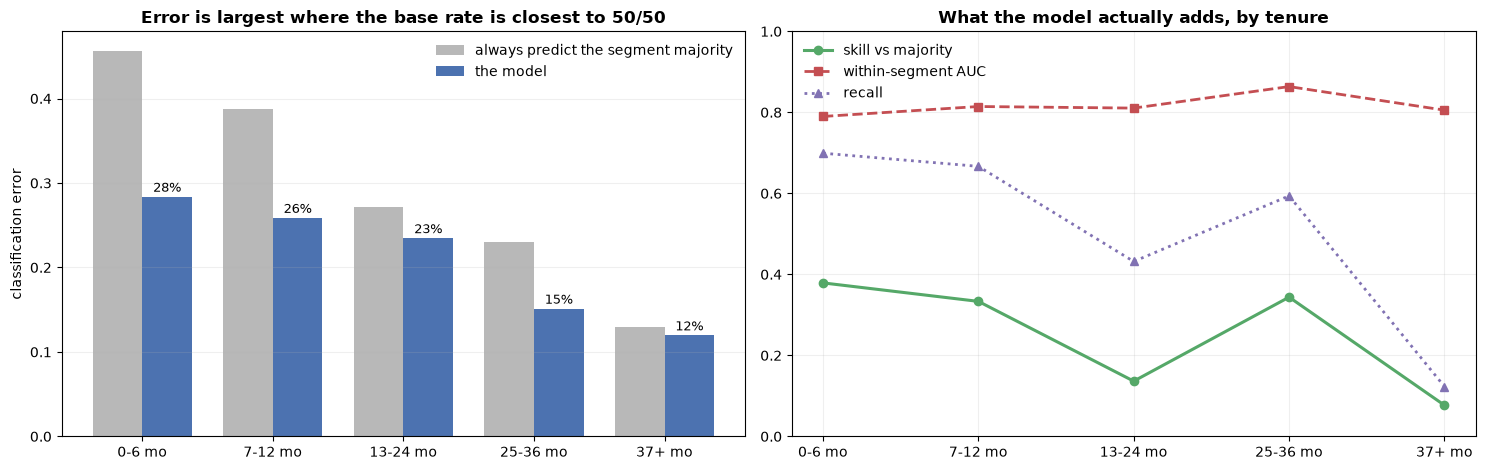

In [22]:
tb = sr[sr.slice == "tenure_band"].copy()
order = ["0-6 mo", "7-12 mo", "13-24 mo", "25-36 mo", "37+ mo"]
tb["order"] = tb.level.map({l: i for i, l in enumerate(order)})
tb = tb.sort_values("order")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(tb))
w = 0.38
axes[0].bar(x - w / 2, tb.baseline_error, w, color="#B8B8B8", label="always predict the segment majority")
axes[0].bar(x + w / 2, tb.error_rate, w, color="#4C72B0", label="the model")
axes[0].set_xticks(x)
axes[0].set_xticklabels(tb.level)
axes[0].set_ylabel("classification error")
axes[0].set_title("Error is largest where the base rate is closest to 50/50", weight="bold")
for xi, (e, b) in enumerate(zip(tb.error_rate, tb.baseline_error)):
    axes[0].text(xi + w / 2, e + 0.006, f"{e:.0%}", ha="center", fontsize=9)
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.2)

axes[1].plot(tb.level, tb.skill_vs_majority, "o-", color="#55A868", lw=2.2, label="skill vs majority")
axes[1].plot(tb.level, tb.auc, "s--", color="#C44E52", lw=2.0, label="within-segment AUC")
axes[1].plot(tb.level, tb.recall, "^:", color="#8172B3", lw=2.0, label="recall")
axes[1].set_ylim(0, 1)
axes[1].set_title("What the model actually adds, by tenure", weight="bold")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.2)
plt.tight_layout()
fig.savefig(PATHS.figures / "03_error_by_tenure.png", dpi=140, bbox_inches="tight")
plt.show()

In [23]:
# What the slice table supports -- computed.
highest_err = tb.loc[tb.error_rate.idxmax()]
best_skill = tb.loc[tb.skill_vs_majority.idxmax()]
worst_skill = tb.loc[tb.skill_vs_majority.idxmin()]
best_recall = tb.loc[tb.recall.idxmax()]
lowest_recall = tb.loc[tb.recall.idxmin()]
overall_err = float(((p_lr >= 0.5) != y_val).mean())
overall_base = min(y_val.mean(), 1 - y_val.mean())

two_year = sr[(sr.slice == "Contract") & (sr.level == "Two year")].iloc[0]

display(Markdown(f"""
**What this shows.** The **{highest_err.level}** tenure band has the highest error rate ({highest_err.error_rate:.1%}, against an overall
{overall_err:.1%}), but it is also the band where {highest_err.churn_rate:.0%} of customers churn, so even always guessing the majority
class would err {highest_err.baseline_error:.1%} of the time. Measured against that baseline the model's skill there is
**{highest_err.skill_vs_majority:.2f}**, its within-band AUC is {highest_err.auc:.2f} and its recall is {highest_err.recall:.0%}.

Across tenure bands, skill is highest in **{best_skill.level}** ({best_skill.skill_vs_majority:.2f}) and lowest in **{worst_skill.level}**
({worst_skill.skill_vs_majority:.2f}); recall is highest in {best_recall.level} ({best_recall.recall:.0%}) and lowest in {lowest_recall.level}
({lowest_recall.recall:.0%}). {"The highest-error band is **not** the band where the model adds least." if highest_err.level != worst_skill.level else "The highest-error band is also the band where the model adds least."}

A "best cohort" by raw error rate can be a cohort where the model does nothing: two-year-contract customers have
{two_year.error_rate:.1%} error but a majority baseline of {two_year.baseline_error:.1%}, skill {two_year.skill_vs_majority:.2f} and recall {two_year.recall:.0%}.
"""))


**What this shows.** The **0-6 mo** tenure band has the highest error rate (28.4%, against an overall
18.5%), but it is also the band where 54% of customers churn, so even always guessing the majority
class would err 45.7% of the time. Measured against that baseline the model's skill there is
**0.38**, its within-band AUC is 0.79 and its recall is 70%.

Across tenure bands, skill is highest in **0-6 mo** (0.38) and lowest in **37+ mo**
(0.08); recall is highest in 0-6 mo (70%) and lowest in 37+ mo
(12%). The highest-error band is **not** the band where the model adds least.

A "best cohort" by raw error rate can be a cohort where the model does nothing: two-year-contract customers have
4.1% error but a majority baseline of 4.1%, skill 0.00 and recall 0%.


---
## 9 · Calibration: are the probabilities trustworthy?

A score of 0.9 should mean "about 90% of these customers churn". Whether a model
is over- or under-confident is **a property of the model, not of its family**, so
the direction is read from the table rather than assumed. Both models are checked.
Notebook 02 serves the logistic regression, so its calibration is what matters.

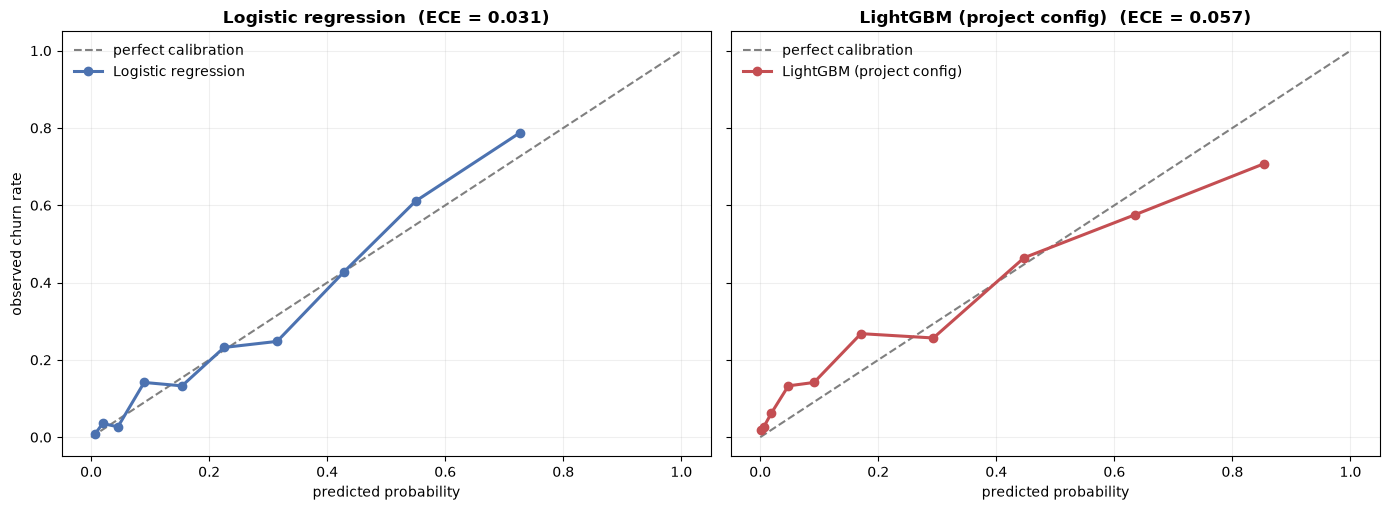

LOGISTIC REGRESSION


,n,mean_predicted,observed_rate,gap,abs_gap
0,113,0.0070,0.0088,-0.0018,0.0018
1,113,0.0195,0.0354,-0.0159,0.0159
2,112,0.0454,0.0268,0.0186,0.0186
3,113,0.0899,0.1416,-0.0517,0.0517
4,113,0.1540,0.1327,0.0212,0.0212
5,112,0.2253,0.2321,-0.0069,0.0069
6,113,0.3150,0.2478,0.0672,0.0672
7,112,0.4290,0.4286,0.0004,0.0004
8,113,0.5497,0.6106,-0.0609,0.0609
9,113,0.7265,0.7876,-0.0611,0.0611


LIGHTGBM (PROJECT CONFIG)


,n,mean_predicted,observed_rate,gap,abs_gap
0,113,0.0017,0.0177,-0.0160,0.0160
1,113,0.0060,0.0265,-0.0206,0.0206
2,112,0.0189,0.0625,-0.0436,0.0436
3,113,0.0476,0.1327,-0.0851,0.0851
4,113,0.0911,0.1416,-0.0505,0.0505
5,112,0.1707,0.2679,-0.0972,0.0972
6,113,0.2933,0.2566,0.0366,0.0366
7,112,0.4471,0.4643,-0.0172,0.0172
8,113,0.6345,0.5752,0.0593,0.0593
9,113,0.8543,0.7080,0.1463,0.1463


- **Logistic regression**: ECE 0.031. In the top three bins predicted minus observed = -0.041 (under-confident); in the bottom three = +0.000 (about right).
- **LightGBM (project config)**: ECE 0.057. In the top three bins predicted minus observed = +0.063 (over-confident); in the bottom three = -0.027 (under-confident).

In [24]:
cal = {k: ev.calibration_table(y_val, proba[k], n_bins=10) for k in ("logreg", "lgbm")}
ece = {k: ev.expected_calibration_error(y_val, proba[k]) for k in ("logreg", "lgbm")}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, key, color in zip(axes, ("logreg", "lgbm"), ("#4C72B0", "#C44E52")):
    c = cal[key]
    ax.plot([0, 1], [0, 1], ls="--", color="grey", label="perfect calibration")
    ax.plot(c.mean_predicted, c.observed_rate, "o-", color=color, lw=2.2, label=LABELS[key])
    ax.set_xlabel("predicted probability")
    ax.set_title(f"{LABELS[key]}  (ECE = {ece[key]:.3f})", weight="bold")
    ax.legend(frameon=False)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("observed churn rate")
plt.tight_layout()
fig.savefig(PATHS.figures / "04_calibration.png", dpi=140, bbox_inches="tight")
plt.show()

for key in ("logreg", "lgbm"):
    print(f"{LABELS[key].upper()}")
    display(cal[key].round(4))

def direction(c):
    top = c.tail(3)
    gap = float((top.mean_predicted - top.observed_rate).mean())
    low = c.head(3)
    low_gap = float((low.mean_predicted - low.observed_rate).mean())
    return gap, low_gap

lines = []
for key in ("logreg", "lgbm"):
    top_gap, low_gap = direction(cal[key])
    lines.append(f"- **{LABELS[key]}**: ECE {ece[key]:.3f}. In the top three bins predicted minus observed = {top_gap:+.3f} "
                 f"({'over-confident' if top_gap > 0.01 else 'under-confident' if top_gap < -0.01 else 'about right'}); "
                 f"in the bottom three = {low_gap:+.3f} ({'over-confident' if low_gap > 0.01 else 'under-confident' if low_gap < -0.01 else 'about right'}).")
display(Markdown("\n".join(lines)))

In [25]:
# Temperature scaling for the shipped model: fit on validation only.
T_fitted, T_curve = ev.fit_temperature(y_val, proba["logreg"])
nll_at_1 = float(T_curve.loc[T_curve.temperature == 1.0, "log_loss"].iloc[0])
display(Markdown(f"""
**Temperature scaling, fitted on the validation set.** Best temperature for the logistic regression: **T = {T_fitted:.2f}**
(log-loss {T_curve.log_loss.min():.4f} at the optimum vs {nll_at_1:.4f} at T = 1.00).
{"T is 1.00: the regularised logistic regression's probabilities are already well scaled and temperature scaling has nothing to correct. The mechanism is kept in the serving layer (and tested), but it is a no-op for this model." if abs(T_fitted - 1.0) < 1e-9 else f"T differs from 1, so scores are {'over' if T_fitted > 1 else 'under'}-confident and the serving layer will apply this temperature."}
"""))


**Temperature scaling, fitted on the validation set.** Best temperature for the logistic regression: **T = 1.00**
(log-loss 0.4116 at the optimum vs 0.4116 at T = 1.00).
T is 1.00: the regularised logistic regression's probabilities are already well scaled and temperature scaling has nothing to correct. The mechanism is kept in the serving layer (and tested), but it is a no-op for this model.


### The threshold is a business parameter, not a model parameter

Every model can produce any operating point by moving the cut. A customer is
worth contacting when

> `P(churn) x success rate x value per month x months > offer cost`

so the best threshold is set by the **cost/benefit ratio**, and it can sit well
below 0.5 (cheap offers) or above it (expensive offers). The economics below are
**illustrative**; the sensitivity grid shows how far the answer moves when they
change. The threshold is chosen on **validation** data only, and §11 then checks
the gain on the **test** set, because a threshold picked *because* it looked best
will look better on the data that picked it than it deserves to.

In [26]:
# These cost assumptions are placeholders. Replace with real commercial numbers
# before using any conclusion from this cell.
ECON = {
    "offer_cost": 100.0,        # cost of extending a retention offer
    "success_rate": 0.40,       # share of flagged churners who would stay
    "monthly_value": 70.0,      # monthly revenue per customer
    "horizon_months": 12,       # planning horizon
}
print("ILLUSTRATIVE economics (not a business recommendation):")
for k, v in ECON.items():
    print(f"  {k:14s} {v}")
print()

sweep = ev.threshold_sweep(y_val, proba["logreg"], **ECON)
best_t = ev.optimal_threshold(sweep)

show_t = sorted({0.10, 0.20, 0.40, 0.50, 0.60, 0.70, round(best_t, 2)})
cols = ["threshold", "n_flagged", "pct_flagged", "precision", "recall", "net_value"]
display(sweep.loc[sweep.threshold.round(2).isin(show_t), cols].round(4))
net_at_half = float(sweep.loc[np.isclose(sweep.threshold, 0.50), "net_value"].iloc[0])
net_at_best = float(sweep["net_value"].max())
print(f"Net-value optimum on validation: threshold = {best_t:.2f}")
print(f"Net value at 0.50               : {net_at_half:,.0f}")
print(f"Net value at the optimum        : {net_at_best:,.0f}   (in-sample: this is the set that chose it)")

ILLUSTRATIVE economics (not a business recommendation):
  offer_cost     100.0
  success_rate   0.4
  monthly_value  70.0
  horizon_months 12



,threshold,n_flagged,pct_flagged,precision,recall,net_value
5,0.1000,712,0.6318,0.3947,0.9398,"23,216.0000"
15,0.2000,546,0.4845,0.4725,0.8629,"32,088.0000"
26,0.3100,395,0.3505,0.5722,0.7559,"36,436.0000"
35,0.4000,303,0.2689,0.6436,0.6522,"35,220.0000"
45,0.5000,219,0.1943,0.7078,0.5184,"30,180.0000"
55,0.6000,127,0.1127,0.7717,0.3278,"20,228.0000"
65,0.7000,63,0.0559,0.8254,0.1739,"11,172.0000"


Net-value optimum on validation: threshold = 0.31
Net value at 0.50               : 30,180
Net value at the optimum        : 36,436   (in-sample: this is the set that chose it)


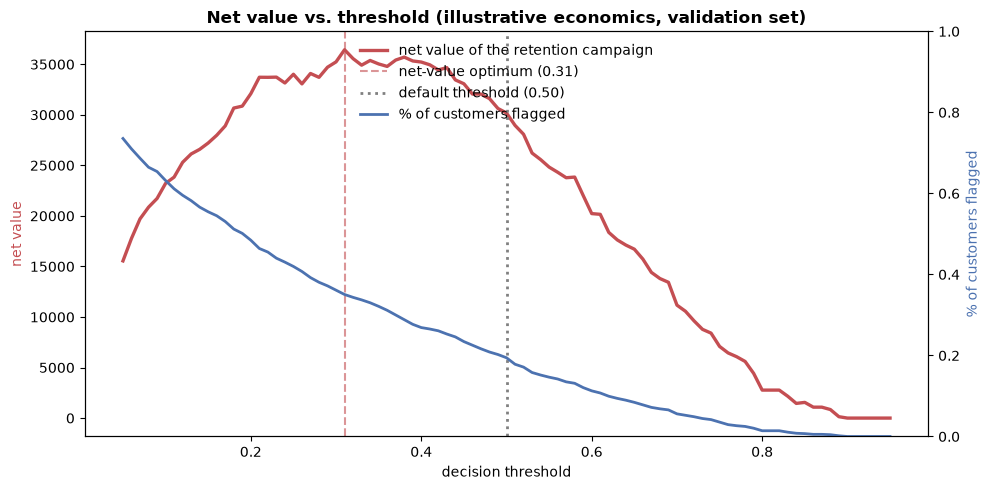

In [27]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(sweep.threshold, sweep.net_value, color="#C44E52", lw=2.4, label="net value of the retention campaign")
ax1.axvline(best_t, ls="--", color="#C44E52", alpha=0.6, label=f"net-value optimum ({best_t:.2f})")
ax1.axvline(0.50, ls=":", color="grey", lw=2, label="default threshold (0.50)")
ax1.set_xlabel("decision threshold")
ax1.set_ylabel("net value", color="#C44E52")

ax2 = ax1.twinx()
ax2.plot(sweep.threshold, sweep.pct_flagged, color="#4C72B0", lw=2, label="% of customers flagged")
ax2.set_ylabel("% of customers flagged", color="#4C72B0")
ax2.set_ylim(0, 1)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, frameon=False, loc="upper center")
ax1.set_title("Net value vs. threshold (illustrative economics, validation set)", weight="bold")
plt.tight_layout()
fig.savefig(PATHS.figures / "05_threshold_economics.png", dpi=140, bbox_inches="tight")
plt.show()

In [28]:
# How far does the optimal threshold move if the economics are different?
grid = ev.threshold_sensitivity(y_val, proba["logreg"], monthly_value=ECON["monthly_value"],
                                horizon_months=ECON["horizon_months"])
pivot = grid.pivot(index="offer_cost", columns="success_rate", values="optimal_threshold")
pivot.columns = [f"success {c:.0%}" for c in pivot.columns]
display(pivot.round(2))
n_above = int((grid.optimal_threshold > 0.5).sum())
edge = float(sweep.threshold.max())
n_edge = int((grid.optimal_threshold >= edge - 1e-9).sum())
display(Markdown(f"""
**Reading the grid.** The profit-optimal threshold ranges from **{grid.optimal_threshold.min():.2f} to {grid.optimal_threshold.max():.2f}**
across these {len(grid)} plausible economics, and is **above 0.5 in {n_above} of them**. So "0.5 is the wrong threshold" is not
a general truth: the right threshold is whatever the cost/benefit ratio says, and 0.5 is optimal only by coincidence.
{f"In {n_edge} cell(s) the optimum sits at {edge:.2f}, the top of the swept range: there the offer is so costly relative to its payoff that the campaign barely pays at any threshold." if n_edge else ""}
"""))

,success 20%,success 40%,success 60%
offer_cost,,,
25.0000,0.2100,0.0600,0.0500
50.0000,0.3100,0.2100,0.0700
100.0000,0.5800,0.3100,0.2100
200.0000,0.9500,0.5800,0.4300
300.0000,0.9500,0.7700,0.5800



**Reading the grid.** The profit-optimal threshold ranges from **0.05 to 0.95**
across these 15 plausible economics, and is **above 0.5 in 6 of them**. So "0.5 is the wrong threshold" is not
a general truth: the right threshold is whatever the cost/benefit ratio says, and 0.5 is optimal only by coincidence.
In 2 cell(s) the optimum sits at 0.95, the top of the swept range: there the offer is so costly relative to its payoff that the campaign barely pays at any threshold.


---
## 10 · Consistency: does the model contradict what we already know?

A model that scores month-to-month new customers as *low* risk has learned
something the business already knows to be false. Each prior states a
**direction**: a "high-risk" group should score *above* the overall average and a
"low-risk" group *below* it, and a violation is a score on the wrong side.

These priors are simple and explicitly debatable. They are a sanity net, not a
ground truth. A detector that has never fired is indistinguishable from one that
cannot, so the last cell feeds it a model with the risk ordering **reversed** and
checks that it does fire.

In [29]:
cons = {k: ex.consistency_audit(val_frame, proba[k], y_val) for k in ("logreg", "lgbm")}
for key in ("logreg", "lgbm"):
    print(LABELS[key].upper() + ("  (shipped)" if key == "logreg" else ""))
    display(cons[key].round(4))
    print(f"  contradictions found: {int((cons[key].severity == 'REVIEW').sum())}\n")

# The detector must be able to fire.
reversed_audit = ex.consistency_audit(val_frame, 1.0 - proba["logreg"], y_val)
n_fired = int((reversed_audit.severity == "REVIEW").sum())
display(Markdown(f"**Sanity check of the detector.** Fed the shipped model's scores *reversed* (high risk becomes low), it flags "
                 f"**{n_fired} of {len(reversed_audit)}** priors as REVIEW. {'It can fire.' if n_fired == len(reversed_audit) else 'It did NOT fire on every prior; the audit is not trustworthy until that is explained.'} "
                 "Agreement on three coarse priors does not imply correctness; it only rules out the loudest class of error."))

LOGISTIC REGRESSION  (shipped)


,prior,expected,n,observed_churn_rate,model_mean_prediction,overall_mean_prediction,model_agrees,severity
0,"month-to-month, tenure <6mo should be a high-r...",high,190,0.5579,0.5089,0.2562,True,ok
1,"2-year contract, tenure >24mo should be low risk",low,245,0.0449,0.0250,0.2562,True,ok
2,no internet service should be low risk,low,244,0.0615,0.0677,0.2562,True,ok


  contradictions found: 0

LIGHTGBM (PROJECT CONFIG)


,prior,expected,n,observed_churn_rate,model_mean_prediction,overall_mean_prediction,model_agrees,severity
0,"month-to-month, tenure <6mo should be a high-r...",high,190,0.5579,0.5390,0.2566,True,ok
1,"2-year contract, tenure >24mo should be low risk",low,245,0.0449,0.0198,0.2566,True,ok
2,no internet service should be low risk,low,244,0.0615,0.0545,0.2566,True,ok


  contradictions found: 0



**Sanity check of the detector.** Fed the shipped model's scores *reversed* (high risk becomes low), it flags **3 of 3** priors as REVIEW. It can fire. Agreement on three coarse priors does not imply correctness; it only rules out the loudest class of error.

---
## 11 · The test set

Everything above used train and validation. The threshold was selected on
validation, so the test set has played no part in any decision and its numbers
carry no selection bias.

- Threshold-free metrics (ROC-AUC, PR-AUC) are reported for **every** model.
- Metrics *at a threshold* are reported only for the shipped model at **its own**
  validation-chosen threshold: that threshold was tuned to the logistic regression's
  score scale, so applying it to the other models would not be a like-for-like
  comparison.
- The profit gain from moving off 0.5 is **re-measured here**, with an interval,
  instead of being quoted from the validation set that picked the threshold.

In [30]:
chosen_threshold = best_t
print(f"Chosen on validation: threshold = {chosen_threshold:.2f}")
print(f"Not used for any decision until now: test split, {len(splits.test):,} rows\n")

p_test = {k: pipe.predict_proba(splits.test)[:, 1] for k, pipe in fitted.items()}
final = []
for key in fitted:
    m = ev.metric_report(y_test, p_test[key], threshold=0.5)
    lo, hi = ev.bootstrap_ci(y_test, p_test[key], metric="roc_auc", n_boot=1200)
    lo_ap, hi_ap = ev.bootstrap_ci(y_test, p_test[key], metric="pr_auc", n_boot=1200)
    final.append({"model": LABELS[key], "roc_auc": m["roc_auc"], "roc_auc 95% CI": f"[{lo:.3f}, {hi:.3f}]",
                  "pr_auc": m["pr_auc"], "pr_auc 95% CI": f"[{lo_ap:.3f}, {hi_ap:.3f}]", "brier": m["brier"]})
display(pd.DataFrame(final).set_index("model").round(4))

val_vs_test = pd.DataFrame({
    "validation ROC-AUC": {LABELS[k]: ev.metric_report(y_val, proba[k])["roc_auc"] for k in fitted},
    "test ROC-AUC": {LABELS[k]: ev.metric_report(y_test, p_test[k])["roc_auc"] for k in fitted},
})
val_vs_test["test - validation"] = val_vs_test["test ROC-AUC"] - val_vs_test["validation ROC-AUC"]
display(val_vs_test.round(4))
print("Test rows are stratified, so these should sit close to the validation numbers; a large")
print("drop would mean the validation set had been used to overfit.")

Chosen on validation: threshold = 0.31
Not used for any decision until now: test split, 1,409 rows



,roc_auc,roc_auc 95% CI,pr_auc,pr_auc 95% CI,brier
model,,,,,
Logistic regression,0.8480,"[0.826, 0.868]",0.6618,"[0.609, 0.711]",0.1348
Random forest,0.8407,"[0.818, 0.862]",0.6394,"[0.586, 0.691]",0.1378
LightGBM (project config),0.8302,"[0.806, 0.853]",0.6226,"[0.567, 0.675]",0.1436
LightGBM (regularised),0.8464,"[0.824, 0.867]",0.6534,"[0.600, 0.703]",0.1357


,validation ROC-AUC,test ROC-AUC,test - validation
Logistic regression,0.8507,0.8480,-0.0027
Random forest,0.8412,0.8407,-0.0005
LightGBM (project config),0.8249,0.8302,0.0053
LightGBM (regularised),0.8500,0.8464,-0.0035


Test rows are stratified, so these should sit close to the validation numbers; a large
drop would mean the validation set had been used to overfit.


In [31]:
# The shipped model at its chosen threshold: the operating point as a workload,
# and the profit gain re-measured out of sample.
pt = p_test["logreg"]
flagged = pt >= chosen_threshold
n_flagged = int(flagged.sum())
precision_t = float((y_test[flagged] == 1).mean())
recall_t = float((flagged & (y_test == 1)).sum() / y_test.sum())     # recall AT THE CHOSEN threshold
recall_half = float(((pt >= 0.5) & (y_test == 1)).sum() / y_test.sum())

print("OPERATING POINT ON TEST DATA (logistic regression)")
print("=" * 68)
print(f"  threshold                    : {chosen_threshold:.2f}")
print(f"  customers flagged            : {n_flagged:,} of {len(splits.test):,} ({n_flagged / len(splits.test):.1%})")
print(f"  precision (flagged right)    : {precision_t:.1%}")
print(f"  recall at {chosen_threshold:.2f} (churners caught): {recall_t:.1%}      [recall at 0.50 would be {recall_half:.1%}]")
print(f"  list size per 1,000 customers: {n_flagged / len(splits.test) * 1000:.0f}")
print("=" * 68)

net_best_t = ev.net_value_at(y_test, pt, chosen_threshold, **ECON)
net_half_t = ev.net_value_at(y_test, pt, 0.50, **ECON)
delta = ev.net_value_delta_ci(y_test, pt, chosen_threshold, 0.50, n_boot=2000, **ECON)
display(Markdown(f"""
**Profit on the test set (illustrative economics).** Net value at the chosen threshold {chosen_threshold:.2f}: **{net_best_t:,.0f}**; at 0.50: **{net_half_t:,.0f}**.
Difference **{delta['delta']:+,.0f}**, 95% bootstrap interval **[{delta['ci_low']:+,.0f}, {delta['ci_high']:+,.0f}]**
({"the interval excludes zero" if delta["excludes_zero"] else "the interval **includes zero**, so this gain is a hypothesis rather than a result"}).
On the validation set that chose the threshold the same comparison read {net_at_best:,.0f} vs {net_at_half:,.0f}
({net_at_best - net_at_half:+,.0f}): {"the out-of-sample gain is smaller, as expected for a threshold picked because it looked best." if delta["delta"] < net_at_best - net_at_half else "the out-of-sample gain is not smaller than the in-sample one."}
"""))

OPERATING POINT ON TEST DATA (logistic regression)
  threshold                    : 0.31
  customers flagged            : 524 of 1,409 (37.2%)
  precision (flagged right)    : 52.7%
  recall at 0.31 (churners caught): 73.8%      [recall at 0.50 would be 52.1%]
  list size per 1,000 customers: 372



**Profit on the test set (illustrative economics).** Net value at the chosen threshold 0.31: **40,336**; at 0.50: **36,220**.
Difference **+4,116**, 95% bootstrap interval **[-709, +8,945]**
(the interval **includes zero**, so this gain is a hypothesis rather than a result).
On the validation set that chose the threshold the same comparison read 36,436 vs 30,180
(+6,256): the out-of-sample gain is smaller, as expected for a threshold picked because it looked best.


In [32]:
# Hand the decision to notebook 02 through a file, so the threshold is derived
# once here and never re-typed.
import json

decision = {
    "threshold": float(chosen_threshold),
    "temperature": float(T_fitted),
    "economics": ECON,
    "selected_on": "validation",
    "model": "logreg",
    "validation_ece": float(ece["logreg"]),
    "test_net_value_gain_vs_0.5": {k: float(v) for k, v in delta.items() if k != "excludes_zero"},
}
(PATHS.artifacts / "decision.json").write_text(json.dumps(decision, indent=2), encoding="utf-8")
print("wrote", (PATHS.artifacts / "decision.json").relative_to(ROOT))
print(json.dumps(decision, indent=2))

wrote artifacts\decision.json
{
  "threshold": 0.31,
  "temperature": 1.0,
  "economics": {
    "offer_cost": 100.0,
    "success_rate": 0.4,
    "monthly_value": 70.0,
    "horizon_months": 12
  },
  "selected_on": "validation",
  "model": "logreg",
  "validation_ece": 0.030646845834125667,
  "test_net_value_gain_vs_0.5": {
    "delta": 4116.0,
    "ci_low": -708.7999999999857,
    "ci_high": 8945.499999999993,
    "p_a_better": 0.9455
  }
}


---
## 12 · Conclusions

Every number in this section is computed from the run above. The text is
assembled by code from the objects that hold the results, so it cannot drift
from them.

In [33]:
lines = []

# 1. which model
lines.append("### What the evidence supports")
for other in others:
    outcome, why = verdict(other)
    lines.append(f"- **Logistic regression vs {LABELS[other]}:** {outcome} ({why}).")

# 2. explanation agreement and faithfulness
f_lr, f_gb = faith["logreg"], faith["lgbm"]
inf_lr = f_lr.ablation[f_lr.ablation.informative_k]
if rho_lr >= 0.7:
    lines.append(f"- **Feature ranking is corroborated** for the shipped model: permutation and SHAP agree at rho = {rho_lr:.2f} "
                 f"(LightGBM: {rho_gb:.2f}).")
else:
    lines.append(f"- **Feature ranking is only partly corroborated** for the shipped model: permutation and SHAP agree at rho = {rho_lr:.2f} "
                 f"(LightGBM: {rho_gb:.2f}). They pick the same top-5 inputs ({len(overlap_lr)} of 5 shared) but not their order; with correlated "
                 "inputs, permutation importance in particular lets one stand in for another. Treat the order as unknown, the top-5 set as supported.")
lines.append(f"- **Explanations vs a random-feature control:** {f_lr.verdict} (logistic regression). {f_gb.verdict} (LightGBM).")
lines.append(f"- **Consistency priors:** {int((cons['logreg'].severity == 'REVIEW').sum())} contradictions for the logistic regression; "
             f"the detector fires {n_fired}/{len(reversed_audit)} when the ordering is reversed.")
lines.append(f"- **Calibration:** the logistic regression's ECE is {ece['logreg']:.3f} and its fitted temperature is {T_fitted:.2f}"
             f"{' (already well scaled)' if abs(T_fitted - 1.0) < 1e-9 else ''}.")

# 3. what is not trustworthy
lines.append("\n### What is *not* trustworthy, and should not be presented as if it were")
lines.append("- **Per-customer counterfactuals.** They show what would move a score, not what would change an outcome.")
rr = ratios
lines.append(f"- **The average partial-dependence curve for tenure.** Between-customer spread / average effect is "
             f"{rr['logreg'][1] / rr['logreg'][0]:.2f}x (logistic regression) and {rr['lgbm'][1] / rr['lgbm'][0]:.2f}x (LightGBM).")
lines.append("- **A raw error rate as a ranking of cohorts.** "
             f"The highest-error tenure band ({highest_err.level}, {highest_err.error_rate:.1%}) has model skill {highest_err.skill_vs_majority:.2f}; "
             f"skill is lowest in {worst_skill.level} ({worst_skill.skill_vs_majority:.2f}).")
lines.append(f"- **A single profit-optimal threshold.** It ranges {grid.optimal_threshold.min():.2f} to {grid.optimal_threshold.max():.2f} "
             f"across plausible economics, and the out-of-sample gain over 0.50 is {delta['delta']:+,.0f} "
             f"({'interval excludes zero' if delta['excludes_zero'] else 'interval includes zero'}).")
lines.append("- **Coefficients read as causal effects.** " + (f"{len(flips)} large coefficient(s) disagree in sign with the raw association." if flips else "No large sign disagreements here, but coefficients remain conditional on every other input."))
display(Markdown("\n".join(lines)))

### What the evidence supports
- **Logistic regression vs Random forest:** **no distinguishable difference** (neither test finds one).
- **Logistic regression vs LightGBM (project config):** logistic regression is **better** (both tests agree).
- **Logistic regression vs LightGBM (regularised):** **no distinguishable difference** (neither test finds one).
- **Feature ranking is only partly corroborated** for the shipped model: permutation and SHAP agree at rho = 0.59 (LightGBM: 0.87). They pick the same top-5 inputs (5 of 5 shared) but not their order; with correlated inputs, permutation importance in particular lets one stand in for another. Treat the order as unknown, the top-5 set as supported.
- **Explanations vs a random-feature control:** Ranking is faithful: at 5 of 5 informative k, shuffling the top-ranked features hurt more than 70% of random feature sets of the same size (1 of 5 also clear the strict 90% bar). (logistic regression). Ranking is faithful: at 5 of 5 informative k, shuffling the top-ranked features hurt more than 70% of random feature sets of the same size (5 of 5 also clear the strict 90% bar). (LightGBM).
- **Consistency priors:** 0 contradictions for the logistic regression; the detector fires 3/3 when the ordering is reversed.
- **Calibration:** the logistic regression's ECE is 0.031 and its fitted temperature is 1.00 (already well scaled).

### What is *not* trustworthy, and should not be presented as if it were
- **Per-customer counterfactuals.** They show what would move a score, not what would change an outcome.
- **The average partial-dependence curve for tenure.** Between-customer spread / average effect is 1.37x (logistic regression) and 1.40x (LightGBM).
- **A raw error rate as a ranking of cohorts.** The highest-error tenure band (0-6 mo, 28.4%) has model skill 0.38; skill is lowest in 37+ mo (0.08).
- **A single profit-optimal threshold.** It ranges 0.05 to 0.95 across plausible economics, and the out-of-sample gain over 0.50 is +4,116 (interval includes zero).
- **Coefficients read as causal effects.** 3 large coefficient(s) disagree in sign with the raw association.

### What I would do next, in priority order

1. **Test a temporal split.** Every number here is a static cross-section; nothing
   estimates drift or decay.
2. **Run a randomised holdout on the retention offer.** The model predicts who
   will *leave*, not who can be *persuaded to stay*; the success rate in the
   economics is exactly the quantity an experiment would measure, and the profit
   case rests on it.
3. **Segment-specific modelling only where the slice analysis shows the model adds
   little** (see §8: skill, not raw error, points to where), rather than where error
   is merely highest.
4. **Fairness review.** `gender` and `SeniorCitizen` are model inputs; whether they
   should be features, and whether flag rates differ by group, is not addressed here.
5. **Collect the missing explanatory variables.** Contract type, tenure, charges and
   internet service are proxies. Service quality, support interactions and price
   changes are plausible causes, and none are present.

### Stated ceiling

This analysis is deliberately scoped: no hyper-parameter search, a single seed,
one dataset, no temporal validation. The conclusions are about **whether this
model's explanations and evaluation can be trusted**, not about the maximum
achievable churn accuracy.